# Assignment 8 — Noise Generation from PDFs

> **Question:** Write a program to generate the following noises using equations derived from the PDFs of noise distributions. Compare your output with those generated using the inbuilt function `imnoise`. Plot the histograms of the generated noise to determine the shape of the distribution.
> 1. Uniform noise
> 2. Gaussian noise
> 3. Erlang noise
> 4. Exponential noise
> 5. Rayleigh noise

**Method — inverse transform sampling.** If $U \sim \text{Uniform}(0,1)$ and $F$ is the CDF of the required distribution, then $z = F^{-1}(U)$ follows that distribution. Only a uniform random number generator is used, and the formulas come from the PDFs (Gonzalez & Woods notation):

| Noise | PDF $p(z)$ | Generating equation |
|---|---|---|
| Uniform | $\frac{1}{b-a},\ a \le z \le b$ | $z = a + (b-a)U$ |
| Gaussian | $\frac{1}{\sqrt{2\pi}\sigma}e^{-(z-\mu)^2/2\sigma^2}$ | Box–Muller: $z = \mu + \sigma\sqrt{-2\ln U_1}\cos(2\pi U_2)$ |
| Erlang (Gamma) | $\frac{a^b z^{b-1}}{(b-1)!}e^{-az},\ z \ge 0$ | sum of $b$ exponentials: $z = -\frac{1}{a}\sum_{i=1}^{b}\ln U_i$ |
| Exponential | $a e^{-az},\ z \ge 0$ | $F(z) = 1 - e^{-az} \Rightarrow z = -\frac{1}{a}\ln(1-U)$ |
| Rayleigh | $\frac{2}{b}(z-a)e^{-(z-a)^2/b},\ z \ge a$ | $F(z) = 1 - e^{-(z-a)^2/b} \Rightarrow z = a + \sqrt{-b\ln(1-U)}$ |

**About `imnoise`:** `imnoise` is a MATLAB function. Its Python equivalent is `skimage.util.random_noise`. Both support only Gaussian, salt & pepper, speckle, Poisson and local-variance noise. So the Gaussian noise is compared with `random_noise(mode='gaussian')`, and every distribution is also compared with NumPy's built-in generators (`np.random.uniform`, `normal`, `gamma`, `exponential`, `rayleigh`).

### Requirements
Run this cell once to install the libraries used in this notebook.

In [ ]:
%pip install numpy matplotlib opencv-python scikit-image

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams['figure.dpi'] = 100


def ask(prompt, default, cast=float):
    """Read a value from the user.
    If the user just presses Enter, types something invalid, or the notebook is
    run non-interactively (no keyboard input possible), the default is used."""
    try:
        text = input(f"{prompt} [default = {default}]: ").strip()
        return cast(text) if text else default
    except Exception:
        print(f"{prompt}: no valid input, using default = {default}")
        return default


def show(images, titles, cols=None, size=4):
    """Display a list of images side by side (grayscale shown on a fixed 0-255 scale)."""
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=1 if im.max() <= 1 else 255)
        else:
            ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

In [2]:
from math import factorial
from skimage.util import random_noise

rng = np.random.default_rng(42)       # only rng.random() (Uniform 0..1) is used for our own generators
N = 200_000                           # number of noise samples for the histograms


# ---------- Our generators (derived from the PDFs) ----------
def uniform_noise(shape, a, b):
    return a + (b - a) * rng.random(shape)

def gaussian_noise(shape, mu, sigma):
    u1, u2 = 1 - rng.random(shape), rng.random(shape)        # 1 - U avoids log(0)
    return mu + sigma * np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)

def erlang_noise(shape, a, b):
    u = 1 - rng.random((b,) + tuple(np.atleast_1d(shape)))
    return -np.log(u).sum(axis=0) / a

def exponential_noise(shape, a):
    return -np.log(1 - rng.random(shape)) / a

def rayleigh_noise(shape, a, b):
    return a + np.sqrt(-b * np.log(1 - rng.random(shape)))


# ---------- Theoretical PDFs ----------
def pdf_uniform(z, a, b):      return np.where((z >= a) & (z <= b), 1 / (b - a), 0)
def pdf_gaussian(z, mu, s):    return np.exp(-(z - mu) ** 2 / (2 * s ** 2)) / (np.sqrt(2 * np.pi) * s)
def pdf_erlang(z, a, b):       return np.where(z >= 0, a ** b * np.abs(z) ** (b - 1) * np.exp(-a * z) / factorial(b - 1), 0)
def pdf_exponential(z, a):     return np.where(z >= 0, a * np.exp(-a * z), 0)
def pdf_rayleigh(z, a, b):     return np.where(z >= a, 2 / b * (z - a) * np.exp(-(z - a) ** 2 / b), 0)

## Noise parameters (in grey-level units, image range 0–255)

In [3]:
P = dict(
    uniform     = dict(a=-40, b=40),
    gaussian    = dict(mu=0, sigma=20),
    erlang      = dict(a=0.1, b=3),         # mean = b/a = 30
    exponential = dict(a=0.05),             # mean = 1/a = 20
    rayleigh    = dict(a=0, b=800),         # mean = a + sqrt(pi*b/4) ~ 25
)

noises = {
    'Uniform': dict(
        mine=uniform_noise(N, **P['uniform']),
        builtin=np.random.default_rng(1).uniform(P['uniform']['a'], P['uniform']['b'], N),
        pdf=lambda z: pdf_uniform(z, **P['uniform']),
        mean=(P['uniform']['a'] + P['uniform']['b']) / 2,
        var=(P['uniform']['b'] - P['uniform']['a']) ** 2 / 12),
    'Gaussian': dict(
        mine=gaussian_noise(N, **P['gaussian']),
        builtin=np.random.default_rng(1).normal(P['gaussian']['mu'], P['gaussian']['sigma'], N),
        pdf=lambda z: pdf_gaussian(z, *P['gaussian'].values()),
        mean=P['gaussian']['mu'], var=P['gaussian']['sigma'] ** 2),
    'Erlang': dict(
        mine=erlang_noise(N, **P['erlang']),
        builtin=np.random.default_rng(1).gamma(P['erlang']['b'], 1 / P['erlang']['a'], N),
        pdf=lambda z: pdf_erlang(z, **P['erlang']),
        mean=P['erlang']['b'] / P['erlang']['a'], var=P['erlang']['b'] / P['erlang']['a'] ** 2),
    'Exponential': dict(
        mine=exponential_noise(N, **P['exponential']),
        builtin=np.random.default_rng(1).exponential(1 / P['exponential']['a'], N),
        pdf=lambda z: pdf_exponential(z, **P['exponential']),
        mean=1 / P['exponential']['a'], var=1 / P['exponential']['a'] ** 2),
    'Rayleigh': dict(
        mine=rayleigh_noise(N, **P['rayleigh']),
        # numpy's rayleigh(scale s) has b = 2 s^2  ->  s = sqrt(b / 2)
        builtin=P['rayleigh']['a'] + np.random.default_rng(1).rayleigh(np.sqrt(P['rayleigh']['b'] / 2), N),
        pdf=lambda z: pdf_rayleigh(z, **P['rayleigh']),
        mean=P['rayleigh']['a'] + np.sqrt(np.pi * P['rayleigh']['b'] / 4),
        var=P['rayleigh']['b'] * (4 - np.pi) / 4),
}

print(f"{'Noise':<12}{'theory mean':>12}{'mine':>9}{'built-in':>10}   {'theory var':>11}{'mine':>9}{'built-in':>10}")
for name, d in noises.items():
    print(f"{name:<12}{d['mean']:>12.2f}{d['mine'].mean():>9.2f}{d['builtin'].mean():>10.2f}   "
          f"{d['var']:>11.1f}{d['mine'].var():>9.1f}{d['builtin'].var():>10.1f}")

Noise        theory mean     mine  built-in    theory var     mine  built-in
Uniform             0.00    -0.00     -0.01         533.3    533.3     532.5
Gaussian            0.00    -0.06     -0.05         400.0    399.7     399.0
Erlang             30.00    30.02     29.90         300.0    300.1     296.9
Exponential        20.00    20.01     19.91         400.0    398.6     394.2
Rayleigh           25.07    25.05     25.02         171.7    172.0     170.6


## Histograms of the generated noise vs the theoretical PDF

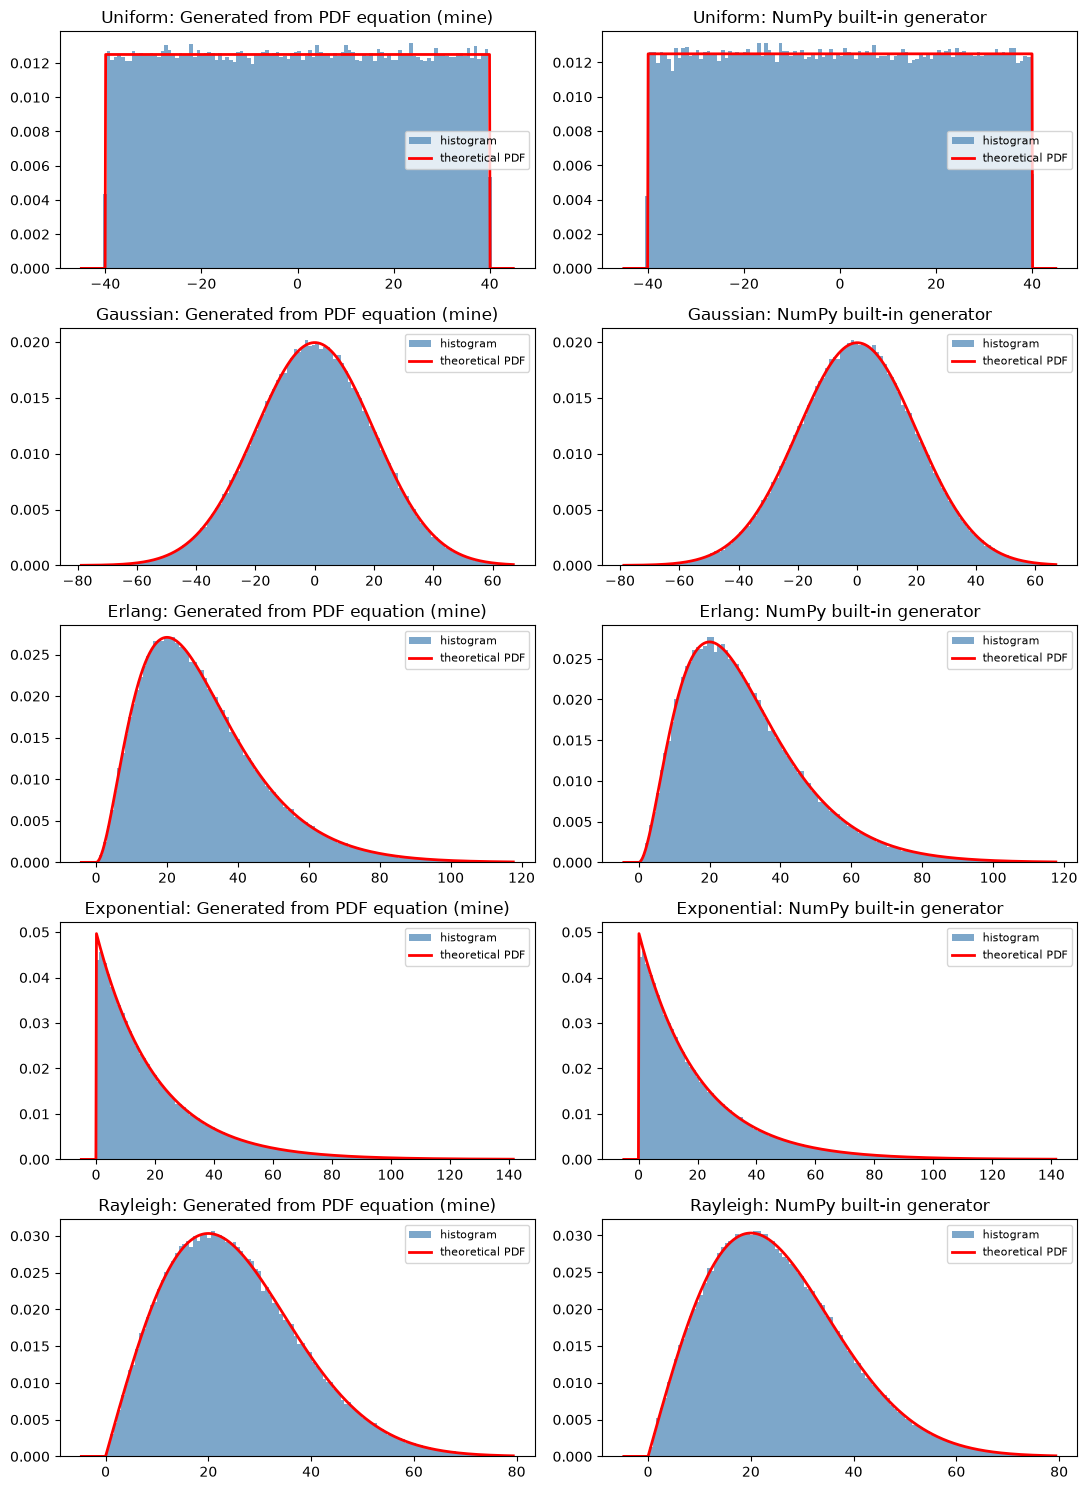

In [4]:
fig, axes = plt.subplots(len(noises), 2, figsize=(11, 3 * len(noises)))
for row, (name, d) in zip(axes, noises.items()):
    lo, hi = np.percentile(np.r_[d['mine'], d['builtin']], [0.01, 99.9])
    z = np.linspace(lo - 5, hi + 5, 800)
    for ax, key, label in zip(row, ['mine', 'builtin'], ['Generated from PDF equation (mine)', 'NumPy built-in generator']):
        ax.hist(d[key], bins=120, range=(lo - 5, hi + 5), density=True, color='steelblue', alpha=0.7, label='histogram')
        ax.plot(z, d['pdf'](z), 'r', lw=2, label='theoretical PDF')
        ax.set_title(f'{name}: {label}'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Adding the noise to an image

A simple three-level test pattern makes the noise shape easy to read from the image histogram, because each flat region turns into a copy of the noise PDF.

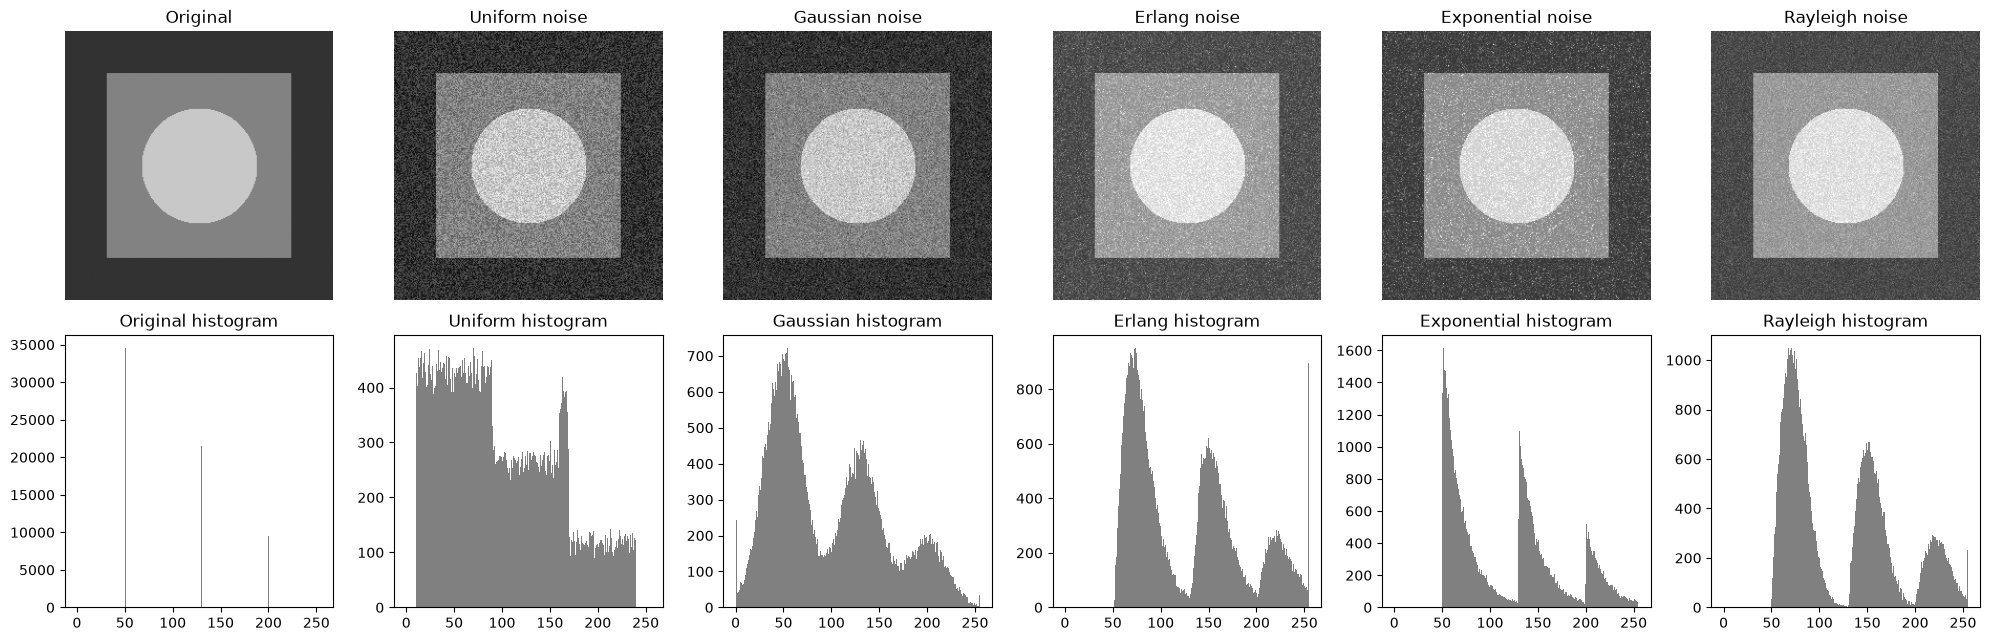

In [5]:
# test pattern: background 50, square 130, circle 200
H = W = 256
pattern = np.full((H, W), 50.0)
pattern[40:216, 40:216] = 130
yy, xx = np.mgrid[:H, :W]
pattern[(yy - 128) ** 2 + (xx - 128) ** 2 < 55 ** 2] = 200

IMAGE_PATH = None   # optionally use your own image
img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE).astype(float) if IMAGE_PATH else pattern

gen_image_noise = {
    'Uniform':     lambda s: uniform_noise(s, **P['uniform']),
    'Gaussian':    lambda s: gaussian_noise(s, **P['gaussian']),
    'Erlang':      lambda s: erlang_noise(s, **P['erlang']),
    'Exponential': lambda s: exponential_noise(s, **P['exponential']),
    'Rayleigh':    lambda s: rayleigh_noise(s, **P['rayleigh']),
}

fig, axes = plt.subplots(2, 6, figsize=(20, 6.5))
axes[0, 0].imshow(img, cmap='gray', vmin=0, vmax=255); axes[0, 0].set_title('Original'); axes[0, 0].axis('off')
axes[1, 0].hist(img.ravel(), bins=256, range=(0, 255), color='gray'); axes[1, 0].set_title('Original histogram')
for i, (name, g) in enumerate(gen_image_noise.items(), start=1):
    noisy = np.clip(img + g(img.shape), 0, 255)
    axes[0, i].imshow(noisy, cmap='gray', vmin=0, vmax=255); axes[0, i].set_title(f'{name} noise'); axes[0, i].axis('off')
    axes[1, i].hist(noisy.ravel(), bins=256, range=(0, 255), color='gray'); axes[1, i].set_title(f'{name} histogram')
plt.tight_layout(); plt.show()

## Comparison with `imnoise` (Python: `skimage.util.random_noise`)

MATLAB: `J = imnoise(I, 'gaussian', m, v)` with `I` in [0, 1].
Python equivalent: `random_noise(I, mode='gaussian', mean=m, var=v)`. Here $\sigma = 20$ grey levels, so $v = (20/255)^2$.

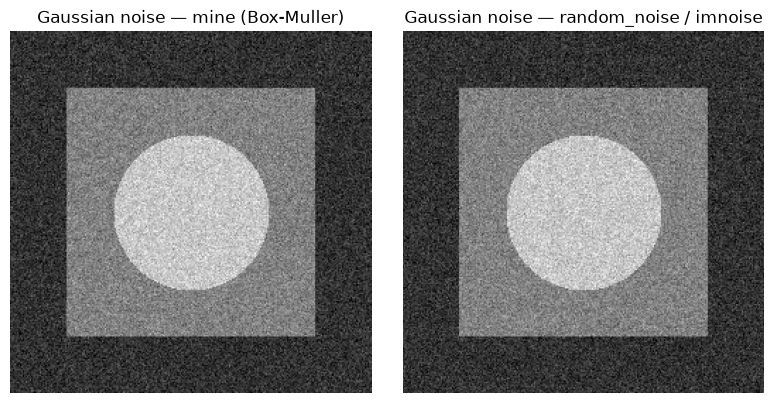

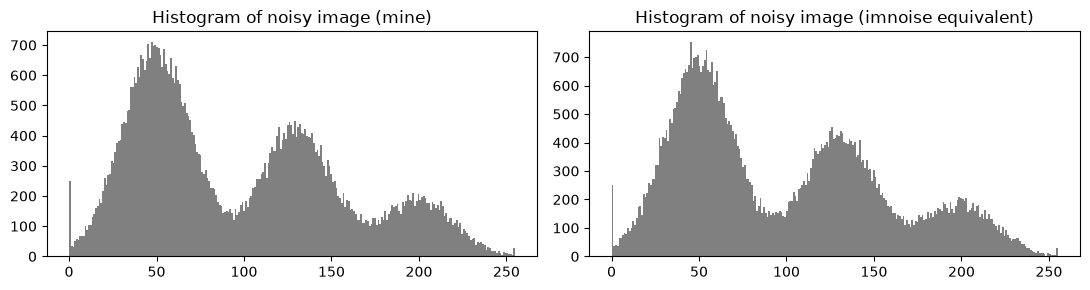

Noise std estimated from the flat background region:
  mine    : 20.06   imnoise eq.: 19.63   (target 20)


In [6]:
sigma = P['gaussian']['sigma']
I01 = img / 255.0
v = (sigma / 255) ** 2

noisy_mine = np.clip(I01 + gaussian_noise(img.shape, 0, sigma / 255), 0, 1)
noisy_imnoise = random_noise(I01, mode='gaussian', mean=0, var=v, rng=7)   # clips to [0, 1] like imnoise

show([(noisy_mine * 255).astype(np.uint8), (noisy_imnoise * 255).astype(np.uint8)],
     ['Gaussian noise — mine (Box-Muller)', 'Gaussian noise — random_noise / imnoise'])

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, im, t in zip(axes, [noisy_mine, noisy_imnoise], ['mine', 'imnoise equivalent']):
    ax.hist(im.ravel() * 255, bins=256, range=(0, 255), color='gray'); ax.set_title(f'Histogram of noisy image ({t})')
plt.tight_layout(); plt.show()

print("Noise std estimated from the flat background region:")
bg = (slice(0, 30), slice(0, 256))
print(f"  mine    : {255 * (noisy_mine[bg] - I01[bg]).std():.2f}   imnoise eq.: {255 * (noisy_imnoise[bg] - I01[bg]).std():.2f}   (target {sigma})")

**Observations:**
- For every noise type, the histogram of the noise generated from the PDF equations matches the theoretical PDF (red curve) and the histogram from the built-in generator. The sample means and variances are also close to the theoretical values.
- The **shape** of the histogram shows the distribution: flat (uniform), bell-shaped (Gaussian), skewed with a peak away from zero (Erlang, Rayleigh), and decaying from zero (exponential).
- In the noisy image histograms, each grey level of the test pattern spreads into the shape of the noise PDF. This is how the type of noise in an image can be estimated from a flat region.
- The Gaussian noise from Box–Muller is statistically the same as the noise from `imnoise` / `random_noise`.